# Search: GA and random search at equal budget

The first nature-inspired search over the genome, against random search with the same number of distinct
genomes trained. Phase 1 scale: 2 runs per method, 300 distinct genomes per run (the full study uses 10 runs of
600 per method, plus PSO).

1. **Genome:** which 8 of the 32 components reach the qubits, the encoding, the depth (1 to 4), and per layer a
   rotation and an entangler. Readout is fixed (⟨Z⟩ on all 8 qubits, weighted sum plus bias).
2. **Fitness:** short training on the 2,000 fitness frames, frame AUC on the inner fitness split, minus λ per
   two-qubit gate. Each genome trains from the same seed, so a genome always gets the same fitness, and a cache
   makes repeats free. The budget counts distinct genomes only.
3. **GA:** tournament selection, crossover with a repair step that keeps the mask at exactly 8, mutation, elitism.
4. **Random search:** random genomes from the same space until the same budget is spent.
5. **Final pick:** the top 3 genomes of each run are retrained on all training frames and scored on validation;
   the best of the 3 is the run's result.

Validation is used only for the final pick; test and Celeb-DF are not touched.

**Inputs (Add Input):** the prep dataset, and the grid notebook's output if you saved it as a dataset (its
`recipe.json` sets the short-training values; otherwise fill them in below).
**Settings:** Accelerator None, Internet On (for pip). About 45 to 90 minutes on Kaggle's CPU.

## 1. Settings

In [1]:
# short-training values chosen by the grid notebook's ranking check.
# Leave as None to read them from recipe.json (grid output added as an input); otherwise type them in.
FIT_LR = None
FIT_EPOCHS = None

N_RUNS = 2                  # independent runs per method (10 in Phase 2)
BUDGET = 300                # distinct genomes trained per run (600 in Phase 2)
POP = 20                    # GA population size
TOURNAMENT = 3
ELITE = 2
P_CROSS = 0.9
P_MUT_GENE = 0.1            # chance that each architecture gene is resampled
P_MUT_MASK = 0.5            # chance of one mask swap (one chosen component out, one other in)
TOP_K = 3                   # genomes per run retrained on all training frames

N_QUBITS = 8
MAX_DEPTH = 4
ENCODINGS = ["RX", "RY", "H+RZ"]
ROTATIONS = ["RY", "RX+RY", "Rot"]
ENTANGLERS = ["none", "chain", "ring", "cz_ring"]
LAMBDA = 0.0006
FIT_PER_CLASS = 1000
FIT_BATCH = 100
LR = 0.01                   # full-training recipe, as in the grid notebook
FULL_EPOCHS = 5
FULL_BATCH = 256

N_BOOTSTRAP = 1000
N_JOBS = 0                  # 0 = one job per CPU core
OUT_DIR = "/kaggle/working/search"
MACHINE_NAME = "kaggle-malak"

## 2. Install and imports

In [2]:
!pip install -q pennylane==0.45.1

In [3]:
import os
import glob
import json
import time
import platform
import multiprocessing as mp

import numpy as np
import pandas as pd
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

torch.set_num_threads(1)
os.makedirs(OUT_DIR, exist_ok=True)
if N_JOBS == 0:
    N_JOBS = os.cpu_count()
print("pennylane", qml.__version__, "torch", torch.__version__, "| parallel jobs:", N_JOBS)

pennylane 0.45.1 torch 2.11.0+cpu | parallel jobs: 4


## 3. Load the prepared features

In [4]:
def find(pattern):
    # search level by level, so the search stays fast however many files the inputs hold
    for depth in range(0, 8):
        hits = glob.glob("/kaggle/input/" + "*/" * depth + pattern)
        if len(hits) > 0:
            return hits[0]
    raise FileNotFoundError(pattern)


angles = {}
rows = {}
for name in ["ffpp_train", "ffpp_val"]:
    path = find(name + "_angles32.npy")
    angles[name] = np.load(path).astype(np.float64)
    rows[name] = pd.read_csv(os.path.join(os.path.dirname(path), name + "_rows.csv"))
    assert len(angles[name]) == len(rows[name]), name
    print(name, angles[name].shape)

is_inner = np.load(find("ffpp_train_is_inner.npy"))
per_comp = pd.read_csv(find("per_component_auc.csv"))
best8 = sorted(per_comp.sort_values("strength_search_train", ascending=False)["component"].head(8).tolist())
first8 = list(range(8))
y_train = rows["ffpp_train"]["label"].to_numpy()
y_val = rows["ffpp_val"]["label"].to_numpy()
val_video = rows["ffpp_val"].groupby(["method", "video_id"]).ngroup().to_numpy()
print("best 8:", best8)

ffpp_train (46076, 32)
ffpp_val (22396, 32)
best 8: [2, 3, 4, 8, 10, 16, 17, 21]


## 4. Fitness training frames

The same 2,000 search-train frames as in the first-circuit notebook (same code, same seed): 1,000 real and
1,000 fake, at most 2 frames per real video and 1 per fake video.

In [5]:
train_rows = rows["ffpp_train"]
st_index = np.where(~is_inner)[0]
st_rows = train_rows.iloc[st_index].copy()
st_rows["row"] = st_index
rng = np.random.default_rng(0)
real_pick = st_rows[st_rows["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st_rows[st_rows["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
fit_index = np.concatenate([rng.choice(real_pick, FIT_PER_CLASS, replace=False),
                            rng.choice(fake_pick, FIT_PER_CLASS, replace=False)])
inner_index = np.where(is_inner)[0]
np.save(os.path.join(OUT_DIR, "fitness_train_rows.npy"), fit_index)
print("fitness training frames", len(fit_index), "| inner frames", len(inner_index))

fitness training frames 2000 | inner frames 6912


## 5. The circuit, built from a genome

Same code as the first-circuit notebook, with the seed as an argument.

In [6]:
TWO_QUBIT_GATES = {"none": 0, "chain": N_QUBITS - 1, "ring": N_QUBITS, "cz_ring": N_QUBITS}
ANGLES_PER_ROTATION = {"RY": 1, "RX+RY": 2, "Rot": 3}


def make_genome(mask, encoding, layers):
    return {"mask": sorted(mask), "encoding": encoding,
            "layers": [{"rotation": r, "entangler": e} for r, e in layers]}


def n_two_qubit(genome):
    return sum(TWO_QUBIT_GATES[layer["entangler"]] for layer in genome["layers"])


def n_params(genome):
    return sum(N_QUBITS * ANGLES_PER_ROTATION[layer["rotation"]] for layer in genome["layers"]) + N_QUBITS + 1


def entangle(kind):
    if kind == "chain":
        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
    elif kind == "ring":
        for i in range(N_QUBITS):
            qml.CNOT(wires=[i, (i + 1) % N_QUBITS])
    elif kind == "cz_ring":
        for i in range(N_QUBITS):
            qml.CZ(wires=[i, (i + 1) % N_QUBITS])


def make_qnode(genome):
    dev = qml.device("default.qubit", wires=N_QUBITS)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, weights):
        for i in range(N_QUBITS):
            if genome["encoding"] == "RX":
                qml.RX(x[:, i], wires=i)
            elif genome["encoding"] == "RY":
                qml.RY(x[:, i], wires=i)
            else:
                qml.Hadamard(wires=i)
                qml.RZ(x[:, i], wires=i)
        for layer, w in zip(genome["layers"], weights):
            for i in range(N_QUBITS):
                if layer["rotation"] == "RY":
                    qml.RY(w[i, 0], wires=i)
                elif layer["rotation"] == "RX+RY":
                    qml.RX(w[i, 0], wires=i)
                    qml.RY(w[i, 1], wires=i)
                else:
                    qml.Rot(w[i, 0], w[i, 1], w[i, 2], wires=i)
            entangle(layer["entangler"])
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

    return circuit


class VQC(torch.nn.Module):
    def __init__(self, genome):
        super().__init__()
        self.circuit = make_qnode(genome)
        self.weights = torch.nn.ParameterList()
        for layer in genome["layers"]:
            k = ANGLES_PER_ROTATION[layer["rotation"]]
            self.weights.append(torch.nn.Parameter(0.1 * torch.randn(N_QUBITS, k, dtype=torch.float64)))
        self.readout = torch.nn.Linear(N_QUBITS, 1, dtype=torch.float64)
        torch.nn.init.normal_(self.readout.weight, std=0.1)
        torch.nn.init.zeros_(self.readout.bias)

    def forward(self, x):
        z = torch.stack(self.circuit(x, list(self.weights)), dim=-1).to(torch.float64)
        return self.readout(z).squeeze(-1)


def train_model(genome, x, y, epochs, batch, lr, seed):
    torch.manual_seed(seed)
    model = VQC(genome)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    xt = torch.tensor(x, dtype=torch.float64)
    yt = torch.tensor(y, dtype=torch.float64)
    gen = torch.Generator().manual_seed(seed)
    for epoch in range(epochs):
        order = torch.randperm(len(xt), generator=gen)
        for start in range(0, len(xt), batch):
            idx = order[start:start + batch]
            opt.zero_grad()
            loss_fn(model(xt[idx]), yt[idx]).backward()
            opt.step()
    return model


def predict(model, x, chunk=4096):
    out = []
    with torch.no_grad():
        for start in range(0, len(x), chunk):
            xb = torch.tensor(x[start:start + chunk], dtype=torch.float64)
            out.append(torch.sigmoid(model(xb)).numpy())
    return np.concatenate(out)


def video_scores(prob):
    df = pd.DataFrame({"video": val_video, "prob": prob, "label": y_val})
    g = df.groupby("video").agg(prob=("prob", "mean"), label=("label", "first"))
    return g["prob"].to_numpy(), g["label"].to_numpy()


def bootstrap_interval(vp, vy):
    rng = np.random.default_rng(0)
    boot = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(vy), len(vy))
        if vy[idx].min() == vy[idx].max():
            continue
        boot.append(roc_auc_score(vy[idx], vp[idx]))
    return np.percentile(boot, 2.5), np.percentile(boot, 97.5)

## 6. Short-training values

In [7]:
if FIT_LR is None or FIT_EPOCHS is None:
    try:
        with open(find("recipe.json")) as f:
            recipe_in = json.load(f)
    except FileNotFoundError:
        raise FileNotFoundError("no recipe.json among the inputs: add the grid output, or set FIT_LR and FIT_EPOCHS")
    assert "fit_lr" in recipe_in, "this recipe.json has no fit_lr; use the one from the grid notebook"
    FIT_LR = recipe_in["fit_lr"]
    FIT_EPOCHS = recipe_in["fit_epochs"]
print("short training: lr", FIT_LR, "| epochs", FIT_EPOCHS, "| batch", FIT_BATCH)

short training: lr 0.03 | epochs 6 | batch 100


## 7. The search genome

A search genome always holds 4 layer slots; only the first `depth` are used. That keeps crossover simple: genes
line up slot by slot. Two genomes that build the same circuit get the same key, so the cache treats them as one.

Option order is not shuffled here: GA and random search pick options uniformly, so the order cannot bias them.
The shuffling rule matters for PSO's continuous decoding in Phase 2.

In [8]:
def random_genome(rng):
    return {"mask": sorted(rng.choice(32, 8, replace=False).tolist()),
            "encoding": ENCODINGS[rng.integers(len(ENCODINGS))],
            "depth": int(rng.integers(1, MAX_DEPTH + 1)),
            "rotations": [ROTATIONS[rng.integers(len(ROTATIONS))] for _ in range(MAX_DEPTH)],
            "entanglers": [ENTANGLERS[rng.integers(len(ENTANGLERS))] for _ in range(MAX_DEPTH)]}


def to_circuit(sg):
    layers = list(zip(sg["rotations"][:sg["depth"]], sg["entanglers"][:sg["depth"]]))
    return make_genome(sg["mask"], sg["encoding"], layers)


def key_of(sg):
    g = to_circuit(sg)
    layers = "-".join(l["rotation"] + "/" + l["entangler"] for l in g["layers"])
    return "m" + ".".join(str(j) for j in g["mask"]) + "|" + g["encoding"] + "|" + layers


def repair_mask(mask, rng):
    # exactly 8 distinct components, sorted
    mask = sorted(set(mask))
    while len(mask) > 8:
        mask.pop(int(rng.integers(len(mask))))
    while len(mask) < 8:
        j = int(rng.integers(32))
        if j not in mask:
            mask.append(j)
    return sorted(mask)


def crossover(a, b, rng):
    # mask: keep components both parents share, fill the rest from either parent's other picks
    shared = [j for j in a["mask"] if j in b["mask"]]
    others = [j for j in a["mask"] + b["mask"] if j not in shared]
    rng.shuffle(others)
    child = {"mask": repair_mask(shared + others[:8 - len(shared)], rng)}
    for gene in ["encoding", "depth"]:
        child[gene] = a[gene] if rng.random() < 0.5 else b[gene]
    for gene in ["rotations", "entanglers"]:
        child[gene] = [a[gene][s] if rng.random() < 0.5 else b[gene][s] for s in range(MAX_DEPTH)]
    return child


def mutate(sg, rng):
    sg = json.loads(json.dumps(sg))
    if rng.random() < P_MUT_MASK:
        out_j = sg["mask"][rng.integers(8)]
        free = [j for j in range(32) if j not in sg["mask"]]
        sg["mask"] = sorted([j for j in sg["mask"] if j != out_j] + [free[rng.integers(len(free))]])
    if rng.random() < P_MUT_GENE:
        sg["encoding"] = ENCODINGS[rng.integers(len(ENCODINGS))]
    if rng.random() < P_MUT_GENE:
        sg["depth"] = int(rng.integers(1, MAX_DEPTH + 1))
    for s in range(MAX_DEPTH):
        if rng.random() < P_MUT_GENE:
            sg["rotations"][s] = ROTATIONS[rng.integers(len(ROTATIONS))]
        if rng.random() < P_MUT_GENE:
            sg["entanglers"][s] = ENTANGLERS[rng.integers(len(ENTANGLERS))]
    return sg


rng = np.random.default_rng(0)
example = random_genome(rng)
print(key_of(example), "| weights", n_params(to_circuit(example)), "| two-qubit gates", n_two_qubit(to_circuit(example)))

m0.1.2.7.8.13.16.21|H+RZ|RX+RY/cz_ring-RX+RY/ring-Rot/none | weights 65 | two-qubit gates 16


## 8. Fitness, the cache and the log

`evaluate` trains every genome not yet in the cache, in parallel, and logs each one. A genome already in the
cache costs nothing and is not counted. Each method run has its own cache, so runs stay independent.

In [9]:
def fitness_task(sg):
    torch.set_num_threads(1)
    start = time.time()
    g = to_circuit(sg)
    cols = g["mask"]
    model = train_model(g, angles["ffpp_train"][fit_index][:, cols], y_train[fit_index], FIT_EPOCHS, FIT_BATCH, FIT_LR, 0)
    auc = roc_auc_score(y_train[inner_index], predict(model, angles["ffpp_train"][inner_index][:, cols]))
    gates = n_two_qubit(g)
    return {"key": key_of(sg), "inner_auc": auc, "fitness": auc - LAMBDA * gates, "two_qubit_gates": gates,
            "n_params": n_params(g), "depth": sg["depth"], "seconds": time.time() - start}


log = []


def evaluate(pool, genomes, cache, method, run, budget_left):
    # train the genomes not yet seen (at most budget_left), return fitness for every genome given
    new = []
    seen = set()
    for sg in genomes:
        k = key_of(sg)
        if k not in cache and k not in seen and len(new) < budget_left:
            new.append(sg)
            seen.add(k)
    for sg, r in zip(new, pool.map(fitness_task, new)):
        r["genome"] = json.dumps(sg)
        cache[r["key"]] = r
        log.append(dict(r, method=method, run=run, eval=len(cache)))
    return [cache[key_of(sg)]["fitness"] if key_of(sg) in cache else None for sg in genomes], len(new)

## 9. Random search

In [10]:
def random_search(pool, run):
    rng = np.random.default_rng(1000 + run)
    cache = {}
    while len(cache) < BUDGET:
        batch = [random_genome(rng) for _ in range(POP)]
        evaluate(pool, batch, cache, "random", run, BUDGET - len(cache))
    return cache

## 10. Genetic algorithm

Generation 0 is a random population. Each later generation keeps the best `ELITE` genomes and fills the rest
with children: two parents by tournament, crossover with repair, then mutation. Children already in the cache
are free, so a generation can cost fewer than `POP` evaluations. If 20 generations in a row add nothing new,
the run stops early and says so.

In [11]:
def tournament(pop, fit, rng):
    idx = rng.choice(len(pop), TOURNAMENT, replace=False)
    return pop[max(idx, key=lambda i: fit[i])]


def genetic_algorithm(pool, run):
    rng = np.random.default_rng(2000 + run)
    cache = {}
    pop = [random_genome(rng) for _ in range(POP)]
    fit, _ = evaluate(pool, pop, cache, "GA", run, BUDGET - len(cache))
    generation = 0
    stale = 0
    while len(cache) < BUDGET:
        generation += 1
        order = np.argsort(fit)[::-1]
        children = [pop[i] for i in order[:ELITE]]
        while len(children) < POP:
            a = tournament(pop, fit, rng)
            b = tournament(pop, fit, rng)
            child = crossover(a, b, rng) if rng.random() < P_CROSS else json.loads(json.dumps(a))
            children.append(mutate(child, rng))
        new_fit, n_new = evaluate(pool, children, cache, "GA", run, BUDGET - len(cache))
        # children past the budget have no fitness; drop them from the population
        keep = [i for i, f in enumerate(new_fit) if f is not None]
        pop = [children[i] for i in keep]
        fit = [new_fit[i] for i in keep]
        stale = stale + 1 if n_new == 0 else 0
        if stale >= 20:
            print("GA run %d stopped early at %d genomes: no new genome in 20 generations" % (run, len(cache)))
            break
    print("GA run %d: %d generations" % (run, generation))
    return cache

## 11. Run both methods

In [12]:
caches = {}
start_all = time.time()
with mp.get_context("fork").Pool(N_JOBS) as pool:
    for run in range(N_RUNS):
        for method, search in [("random", random_search), ("GA", genetic_algorithm)]:
            t = time.time()
            cache = search(pool, run)
            caches[(method, run)] = cache
            best = max(cache.values(), key=lambda r: r["fitness"])
            print("%-6s run %d: %d genomes, best fitness %.3f (inner AUC %.3f), %.1f min"
                  % (method, run, len(cache), best["fitness"], best["inner_auc"], (time.time() - t) / 60))
            pd.DataFrame(log).to_csv(os.path.join(OUT_DIR, "search_log.csv"), index=False)
print("search done in %.1f min" % ((time.time() - start_all) / 60))

random run 0: 300 genomes, best fitness 0.673 (inner AUC 0.673), 26.6 min
GA run 0: 19 generations
GA     run 0: 300 genomes, best fitness 0.716 (inner AUC 0.716), 18.4 min
random run 1: 300 genomes, best fitness 0.680 (inner AUC 0.680), 27.4 min
GA run 1: 20 generations
GA     run 1: 300 genomes, best fitness 0.717 (inner AUC 0.717), 19.5 min
search done in 92.0 min


## 12. Convergence: best fitness so far against genomes trained

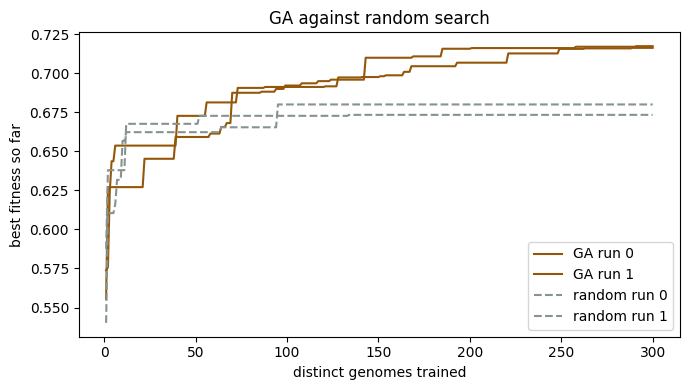

method  run  genomes  best_fitness  mean_fitness  mean_gates  seconds_per_eval
    GA    0      300         0.716         0.667       5.300            13.194
    GA    1      300         0.717         0.667       4.487            14.046
random    0      300         0.673         0.600      14.193            19.105
random    1      300         0.680         0.601      14.037            19.356


In [13]:
log_df = pd.DataFrame(log)
fig, ax = plt.subplots(figsize=(7, 4))
for (method, run), g in log_df.groupby(["method", "run"]):
    g = g.sort_values("eval")
    ax.plot(g["eval"], g["fitness"].cummax(), linestyle="-" if method == "GA" else "--",
            color="#94570A" if method == "GA" else "#86938F", label="%s run %d" % (method, run))
ax.set_xlabel("distinct genomes trained")
ax.set_ylabel("best fitness so far")
ax.set_title("GA against random search")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "convergence.png"), dpi=150)
plt.show()

summary = log_df.groupby(["method", "run"]).agg(genomes=("eval", "max"), best_fitness=("fitness", "max"),
                                                 mean_fitness=("fitness", "mean"), mean_gates=("two_qubit_gates", "mean"),
                                                 seconds_per_eval=("seconds", "mean")).reset_index()
print(summary.round(3).to_string(index=False))

## 13. Final pick: retrain the top 3 of each run on all training frames

The best of thousands of noisy fitness scores is optimistic, so each run's top 3 genomes are trained with the
full recipe on all 360 training pairs and scored on validation. The best of the 3 on validation is the run's
final circuit.

In [14]:
def retrain_task(item):
    torch.set_num_threads(1)
    method, run, rank, sg = item
    g = to_circuit(sg)
    start = time.time()
    model = train_model(g, angles["ffpp_train"][:, g["mask"]], y_train, FULL_EPOCHS, FULL_BATCH, LR, 0)
    prob = predict(model, angles["ffpp_val"][:, g["mask"]])
    vp, vy = video_scores(prob)
    lo, hi = bootstrap_interval(vp, vy)
    return {"method": method, "run": run, "rank": rank, "key": key_of(sg), "frame_auc_val": roc_auc_score(y_val, prob),
            "video_auc_val": roc_auc_score(vy, vp), "video_ci_low": lo, "video_ci_high": hi,
            "two_qubit_gates": n_two_qubit(g), "n_params": n_params(g), "minutes": (time.time() - start) / 60}


items = []
for (method, run), cache in caches.items():
    top = sorted(cache.values(), key=lambda r: r["fitness"], reverse=True)[:TOP_K]
    for rank, r in enumerate(top):
        items.append((method, run, rank + 1, json.loads(r["genome"])))
with mp.get_context("fork").Pool(N_JOBS) as pool:
    final = pd.DataFrame(pool.map(retrain_task, items))
final.to_csv(os.path.join(OUT_DIR, "top_retrained.csv"), index=False)
print(final.drop(columns=["minutes"]).round(3).to_string(index=False))

picks = final.loc[final.groupby(["method", "run"])["video_auc_val"].idxmax()]
picks.to_csv(os.path.join(OUT_DIR, "final_picks.csv"), index=False)
print("\nfinal circuit per run (best of its top 3 on validation):")
print(picks[["method", "run", "key", "video_auc_val", "video_ci_low", "video_ci_high", "two_qubit_gates"]]
      .round(3).to_string(index=False))

method  run  rank                                   key  frame_auc_val  video_auc_val  video_ci_low  video_ci_high  two_qubit_gates  n_params
random    0     1   m0.5.8.17.18.20.21.26|RY|RX+RY/none          0.648          0.661         0.614          0.707                0        25
random    0     2    m2.4.5.8.9.10.23.24|RY|Rot/cz_ring          0.652          0.667         0.618          0.716                8        33
random    0     3   m2.8.9.17.23.25.30.31|RX|RY/cz_ring          0.656          0.668         0.621          0.716                8        17
    GA    0     1   m3.8.9.10.17.21.23.24|H+RZ|Rot/none          0.685          0.702         0.657          0.743                0        33
    GA    0     2    m3.8.9.10.17.21.23.24|H+RZ|RY/none          0.681          0.699         0.653          0.741                0        17
    GA    0     3     m3.8.9.10.17.21.23.24|RX|Rot/none          0.684          0.703         0.657          0.743                0        33
random

## 14. Where the best grid circuit stands

If the grid output is among the inputs, its best circuit is printed for comparison. With 2 runs per method this
is a first look, not a test: the statistics need the 10 runs of Phase 2.

In [15]:
try:
    grid_summary = pd.read_csv(find("grid_summary.csv"))
    b = grid_summary.sort_values("video_auc_mean", ascending=False).iloc[0]
    print("best grid circuit: %s, validation video AUC %.3f (mean over seeds)" % (b["circuit"], b["video_auc_mean"]))
except FileNotFoundError:
    print("grid output not among the inputs; compare by hand with grid_summary.csv")
for method in ["random", "GA"]:
    p = picks[picks["method"] == method]["video_auc_val"]
    print("%-6s final circuits: %s" % (method, ", ".join("%.3f" % v for v in p)))

best grid circuit: best 8, depth 2, none, validation video AUC 0.713 (mean over seeds)
random final circuits: 0.668, 0.688
GA     final circuits: 0.703, 0.715


## 15. Run log

In [16]:
info = {
    "finished": time.strftime("%Y-%m-%d %H:%M:%S"),
    "machine": MACHINE_NAME,
    "n_runs": N_RUNS, "budget": BUDGET, "pop": POP, "tournament": TOURNAMENT, "elite": ELITE,
    "p_cross": P_CROSS, "p_mut_gene": P_MUT_GENE, "p_mut_mask": P_MUT_MASK, "top_k": TOP_K,
    "fit_lr": FIT_LR, "fit_epochs": FIT_EPOCHS, "fit_batch": FIT_BATCH, "lambda": LAMBDA,
    "lr": LR, "full_epochs": FULL_EPOCHS, "full_batch": FULL_BATCH, "n_jobs": N_JOBS,
    "total_minutes": round((time.time() - start_all) / 60, 1),
    "python": platform.python_version(), "pennylane": qml.__version__, "torch": torch.__version__,
}
with open(os.path.join(OUT_DIR, "runs.jsonl"), "a") as f:
    f.write(json.dumps(info) + "\n")
print(sorted(os.listdir(OUT_DIR)))

['convergence.png', 'final_picks.csv', 'fitness_train_rows.npy', 'runs.jsonl', 'search_log.csv', 'top_retrained.csv']
